<div align="center">

# University of Moratuwa

## EN3160 – Image Processing and Computer Vision
<img src='logo.png'>

### Assignment 03

### Neural Network

<b>Name:</b> G.R.G.K. Dissanayake

<b>Index Number: </b>230159B

<b>Submission Date:</b> 18 October 2026
</div>

#### GitHub Repository

The Python implementations and Jupyter Notebooks developed for this assignment are available in the following GitHub repository:

**GitHub Repository:**  
[Image Processing and Computer Vision](https://github.com/raaz-04/Image-Processing-and-Computer-Vision)

The repository contains the implementations, image-processing experiments and supporting image files used throughout the coursework.

## Imports and device setup

In [5]:
import os
import copy
import time
import zipfile
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets, models
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu126
Torchvision: 0.29.1+cu126
Device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


# Question 1 — Dense network with a 100-node sigmoid hidden layer

The original assignment uses CIFAR-10 images and manually computed gradients. Each image is flattened from 3 × 32 × 32 into 3,072 features. The network is:

- Input: 3,072 features
- Hidden: 100 units with sigmoid activation
- Output: 10 class logits
- Loss: cross-entropy
- Training duration: 10 epochs

For numerical stability, the cross-entropy calculation uses `log_softmax` on the output logits. The gradients below are derived manually; no `loss.backward()` or optimizer is used for this question.

In [6]:
# CIFAR-10 data
q1_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

q1_train_set = datasets.CIFAR10(root="./data", train=True, download=True, transform=q1_transform)
q1_test_set = datasets.CIFAR10(root="./data", train=False, download=True, transform=q1_transform)

q1_train_loader = DataLoader(q1_train_set, batch_size=128, shuffle=True, num_workers=2, pin_memory=torch.cuda.is_available())
q1_test_loader = DataLoader(q1_test_set, batch_size=256, shuffle=False, num_workers=2, pin_memory=torch.cuda.is_available())

q1_classes = q1_train_set.classes
Din, H, K = 3 * 32 * 32, 100, 10

# Manual parameters on selected device
W1 = (torch.randn(Din, H, device=device) * np.sqrt(2.0 / Din)).requires_grad_(False)
b1 = torch.zeros(H, device=device)
W2 = (torch.randn(H, K, device=device) * np.sqrt(2.0 / H)).requires_grad_(False)
b2 = torch.zeros(K, device=device)

q1_epochs = 10
q1_lr = 0.05
q1_train_losses = []
q1_train_accs = []
q1_test_accs = []

def q1_evaluate(loader):
    correct, total, loss_sum = 0, 0, 0.0
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device).view(images.size(0), -1)
            labels = labels.to(device)
            hidden = torch.sigmoid(images @ W1 + b1)
            logits = hidden @ W2 + b2
            loss = F.cross_entropy(logits, labels)
            loss_sum += loss.item() * labels.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    return loss_sum / total, 100.0 * correct / total

for epoch in range(q1_epochs):
    W1.zero_() if False else None
    total_loss, total_correct, total = 0.0, 0, 0
    for images, labels in q1_train_loader:
        x = images.to(device).view(images.size(0), -1)
        y = labels.to(device)
        n = x.size(0)

        # Forward pass
        z1 = x @ W1 + b1
        h = torch.sigmoid(z1)
        logits = h @ W2 + b2
        loss = F.cross_entropy(logits, y)

        # Manual derivative of cross-entropy with softmax
        probs = torch.softmax(logits, dim=1)
        probs[torch.arange(n, device=device), y] -= 1.0
        d_logits = probs / n

        dW2 = h.T @ d_logits
        db2 = d_logits.sum(dim=0)
        d_hidden = d_logits @ W2.T
        d_z1 = d_hidden * h * (1.0 - h)
        dW1 = x.T @ d_z1
        db1 = d_z1.sum(dim=0)

        # Parameter update
        with torch.no_grad():
            W1 -= q1_lr * dW1
            b1 -= q1_lr * db1
            W2 -= q1_lr * dW2
            b2 -= q1_lr * db2

        total_loss += loss.item() * n
        total_correct += (logits.argmax(dim=1) == y).sum().item()
        total += n

    train_loss = total_loss / total
    train_acc = 100.0 * total_correct / total
    _, test_acc = q1_evaluate(q1_test_loader)
    q1_train_losses.append(train_loss)
    q1_train_accs.append(train_acc)
    q1_test_accs.append(test_acc)
    print(f"Epoch {epoch+1:02d}/{q1_epochs} | loss={train_loss:.4f} | train acc={train_acc:.2f}% | test acc={test_acc:.2f}%")

q1_final_train_loss, q1_final_train_acc = q1_evaluate(q1_train_loader)
q1_final_test_loss, q1_final_test_acc = q1_evaluate(q1_test_loader)
print(f"\nQuestion 1 final training accuracy: {q1_final_train_acc:.2f}%")
print(f"Question 1 final test accuracy: {q1_final_test_acc:.2f}%")

100%|██████████| 170M/170M [57:25<00:00, 49.5kB/s]   


Epoch 01/10 | loss=1.8976 | train acc=34.46% | test acc=37.47%
Epoch 02/10 | loss=1.7690 | train acc=38.84% | test acc=39.27%
Epoch 03/10 | loss=1.7265 | train acc=40.53% | test acc=40.86%
Epoch 04/10 | loss=1.6964 | train acc=41.61% | test acc=41.28%
Epoch 05/10 | loss=1.6733 | train acc=42.51% | test acc=42.00%
Epoch 06/10 | loss=1.6534 | train acc=43.18% | test acc=42.53%
Epoch 07/10 | loss=1.6343 | train acc=43.98% | test acc=43.03%
Epoch 08/10 | loss=1.6179 | train acc=44.56% | test acc=43.22%
Epoch 09/10 | loss=1.6028 | train acc=45.13% | test acc=43.60%
Epoch 10/10 | loss=1.5876 | train acc=45.66% | test acc=43.99%

Question 1 final training accuracy: 46.20%
Question 1 final test accuracy: 43.99%


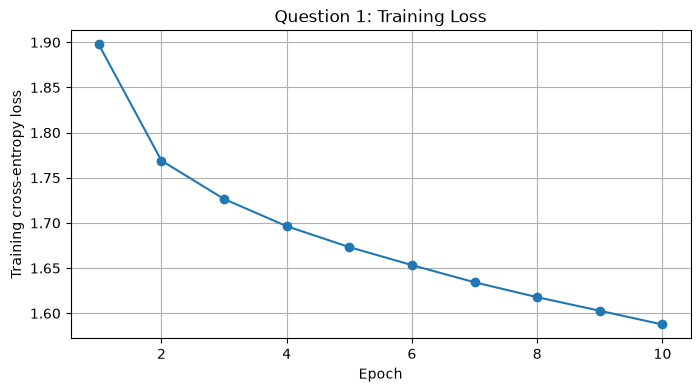

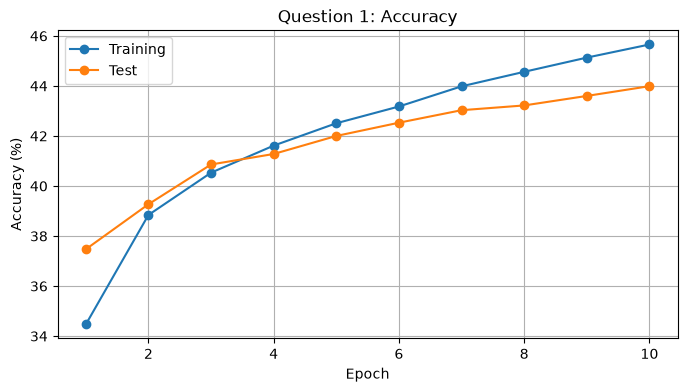

In [7]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, q1_epochs + 1), q1_train_losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training cross-entropy loss")
plt.title("Question 1: Training Loss")
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(range(1, q1_epochs + 1), q1_train_accs, marker="o", label="Training")
plt.plot(range(1, q1_epochs + 1), q1_test_accs, marker="o", label="Test")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Question 1: Accuracy")
plt.legend()
plt.grid(True)
plt.show()

### Question 1 — Answer / discussion

The model uses one hidden layer of 100 sigmoid units and a 10-unit output layer. Cross-entropy is applied to the output logits. Backpropagation is implemented manually using the softmax-cross-entropy gradient and the sigmoid derivative, `h * (1 - h)`.

- Training accuracy after epoch 10: 46.20%
- Test accuracy after epoch 10: 43.99%

The training and test accuracy curves show how performance changes over the 10 epochs. If training accuracy is higher than test accuracy, this can indicate limited generalization or overfitting. A dense network also ignores the spatial structure of images, so it is usually less suitable for image classification than a CNN.

# Question 2 — LeNet-5 and a modern CNN on MNIST

Both models are trained for 10 epochs using the same MNIST train/test split. The notebook records per-epoch training/test loss and accuracy, plots the curves, and produces a test-set confusion matrix for each model.

In [8]:
q2_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

q2_train_set = datasets.MNIST(root="./data", train=True, download=True, transform=q2_transform)
q2_test_set = datasets.MNIST(root="./data", train=False, download=True, transform=q2_transform)

q2_train_loader = DataLoader(q2_train_set, batch_size=128, shuffle=True, num_workers=2, pin_memory=torch.cuda.is_available())
q2_test_loader = DataLoader(q2_test_set, batch_size=256, shuffle=False, num_workers=2, pin_memory=torch.cuda.is_available())
mnist_classes = [str(i) for i in range(10)]
print("MNIST train images:", len(q2_train_set), "| test images:", len(q2_test_set))

100%|██████████| 9.91M/9.91M [00:03<00:00, 3.23MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 95.8kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 902kB/s] 
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.18MB/s]

MNIST train images: 60000 | test images: 10000


In [9]:
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5),
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            nn.Conv2d(6, 16, kernel_size=5),
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2, stride=2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 4 * 4, 120),
            nn.Tanh(),
            nn.Linear(120, 84),
            nn.Tanh(),
            nn.Linear(84, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


class ModernSmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Dropout2d(0.25),
            nn.AdaptiveAvgPool2d((3, 3))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 3 * 3, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, total_correct, total = 0.0, 0, 0
    all_labels, all_preds = [], []

    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            preds = logits.argmax(dim=1)
            total_correct += (preds == labels).sum().item()
            total += batch_size
            all_labels.extend(labels.detach().cpu().numpy())
            all_preds.extend(preds.detach().cpu().numpy())

    return total_loss / total, 100.0 * total_correct / total, np.array(all_labels), np.array(all_preds)


def train_mnist_model(model, model_name, epochs=10, lr=0.001):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}

    for epoch in range(epochs):
        tr_loss, tr_acc, _, _ = run_epoch(model, q2_train_loader, criterion, optimizer)
        te_loss, te_acc, _, _ = run_epoch(model, q2_test_loader, criterion)
        history["train_loss"].append(tr_loss)
        history["test_loss"].append(te_loss)
        history["train_acc"].append(tr_acc)
        history["test_acc"].append(te_acc)
        print(f"{model_name} | Epoch {epoch+1:02d}/{epochs} | train loss {tr_loss:.4f} acc {tr_acc:.2f}% | test loss {te_loss:.4f} acc {te_acc:.2f}%")

    test_loss, test_acc, y_true, y_pred = run_epoch(model, q2_test_loader, criterion)
    print(f"\n{model_name} final test accuracy: {test_acc:.2f}%")
    return model, history, y_true, y_pred


lenet_model, lenet_history, lenet_y_true, lenet_y_pred = train_mnist_model(LeNet5(), "LeNet-5", epochs=10)
modern_model, modern_history, modern_y_true, modern_y_pred = train_mnist_model(ModernSmallCNN(), "Modern CNN", epochs=10)

LeNet-5 | Epoch 01/10 | train loss 0.3405 acc 90.53% | test loss 0.1093 acc 96.80%
LeNet-5 | Epoch 02/10 | train loss 0.0868 acc 97.36% | test loss 0.0598 acc 98.10%
LeNet-5 | Epoch 03/10 | train loss 0.0585 acc 98.21% | test loss 0.0520 acc 98.44%
LeNet-5 | Epoch 04/10 | train loss 0.0453 acc 98.55% | test loss 0.0382 acc 98.69%
LeNet-5 | Epoch 05/10 | train loss 0.0368 acc 98.86% | test loss 0.0489 acc 98.40%
LeNet-5 | Epoch 06/10 | train loss 0.0307 acc 99.06% | test loss 0.0322 acc 98.92%
LeNet-5 | Epoch 07/10 | train loss 0.0262 acc 99.16% | test loss 0.0349 acc 98.92%
LeNet-5 | Epoch 08/10 | train loss 0.0222 acc 99.33% | test loss 0.0278 acc 99.12%
LeNet-5 | Epoch 09/10 | train loss 0.0192 acc 99.41% | test loss 0.0323 acc 98.96%
LeNet-5 | Epoch 10/10 | train loss 0.0165 acc 99.51% | test loss 0.0339 acc 98.92%

LeNet-5 final test accuracy: 98.92%
Modern CNN | Epoch 01/10 | train loss 0.2765 acc 91.74% | test loss 0.0561 acc 98.29%
Modern CNN | Epoch 02/10 | train loss 0.0888 ac

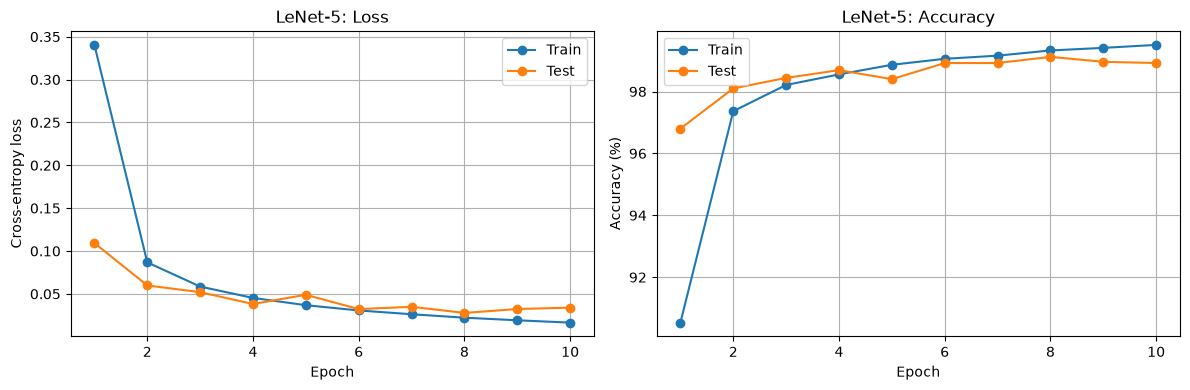

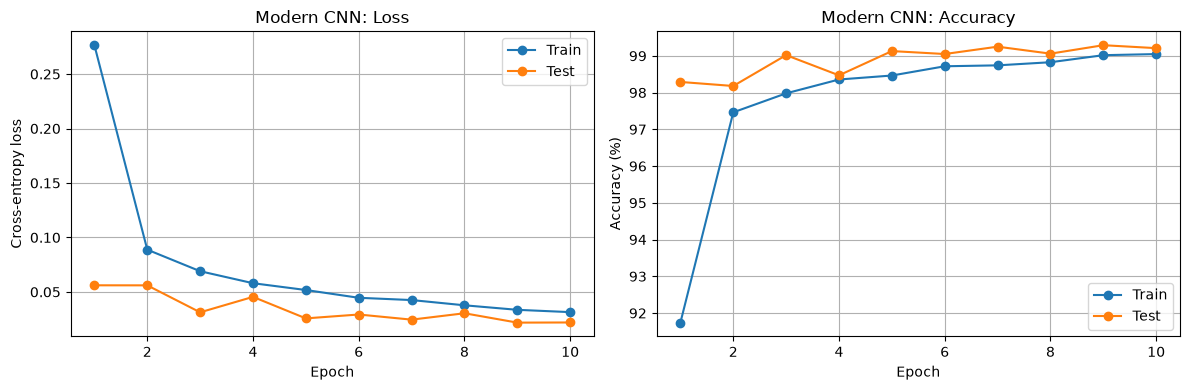

In [10]:
def plot_history(history, name):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs, history["train_loss"], marker="o", label="Train")
    axes[0].plot(epochs, history["test_loss"], marker="o", label="Test")
    axes[0].set_title(f"{name}: Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Cross-entropy loss")
    axes[0].grid(True)
    axes[0].legend()

    axes[1].plot(epochs, history["train_acc"], marker="o", label="Train")
    axes[1].plot(epochs, history["test_acc"], marker="o", label="Test")
    axes[1].set_title(f"{name}: Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy (%)")
    axes[1].grid(True)
    axes[1].legend()
    plt.tight_layout()
    plt.show()

plot_history(lenet_history, "LeNet-5")
plot_history(modern_history, "Modern CNN")

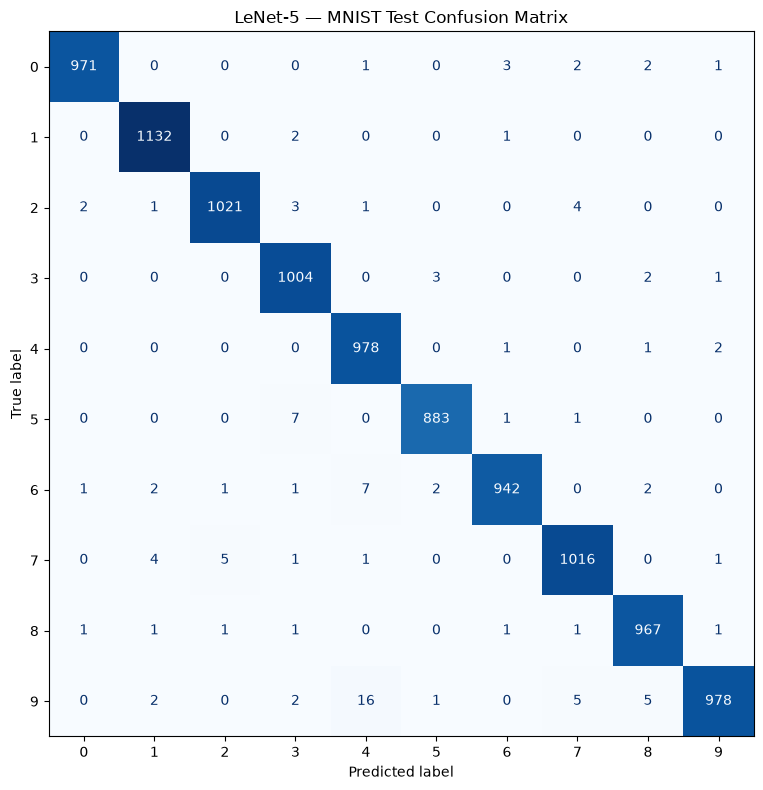

              precision    recall  f1-score   support

           0     0.9959    0.9908    0.9934       980
           1     0.9912    0.9974    0.9943      1135
           2     0.9932    0.9893    0.9913      1032
           3     0.9833    0.9941    0.9887      1010
           4     0.9741    0.9959    0.9849       982
           5     0.9933    0.9899    0.9916       892
           6     0.9926    0.9833    0.9879       958
           7     0.9874    0.9883    0.9878      1028
           8     0.9877    0.9928    0.9903       974
           9     0.9939    0.9693    0.9814      1009

    accuracy                         0.9892     10000
   macro avg     0.9893    0.9891    0.9892     10000
weighted avg     0.9893    0.9892    0.9892     10000



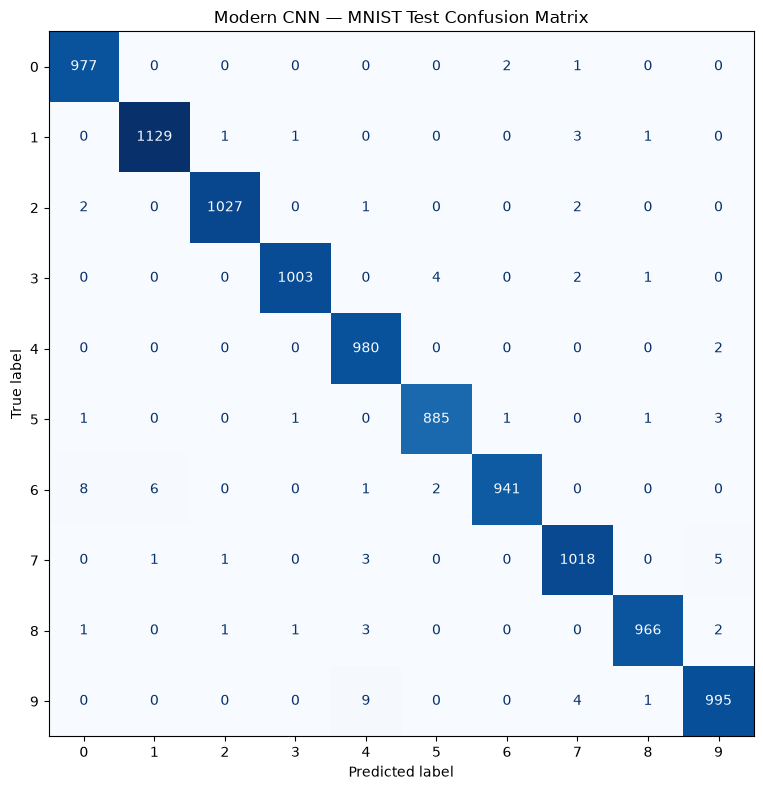

              precision    recall  f1-score   support

           0     0.9879    0.9969    0.9924       980
           1     0.9938    0.9947    0.9943      1135
           2     0.9971    0.9952    0.9961      1032
           3     0.9970    0.9931    0.9950      1010
           4     0.9829    0.9980    0.9904       982
           5     0.9933    0.9922    0.9927       892
           6     0.9968    0.9823    0.9895       958
           7     0.9883    0.9903    0.9893      1028
           8     0.9959    0.9918    0.9938       974
           9     0.9881    0.9861    0.9871      1009

    accuracy                         0.9921     10000
   macro avg     0.9921    0.9920    0.9921     10000
weighted avg     0.9921    0.9921    0.9921     10000

Final accuracy comparison
LeNet-5 test accuracy: 98.92%
Modern CNN test accuracy: 99.21%


In [11]:
def show_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(10)))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=mnist_classes)
    fig, ax = plt.subplots(figsize=(8, 8))
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(title)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
    print(classification_report(y_true, y_pred, digits=4, zero_division=0))

show_confusion(lenet_y_true, lenet_y_pred, "LeNet-5 — MNIST Test Confusion Matrix")
show_confusion(modern_y_true, modern_y_pred, "Modern CNN — MNIST Test Confusion Matrix")

print("Final accuracy comparison")
print(f"LeNet-5 test accuracy: {lenet_history['test_acc'][-1]:.2f}%")
print(f"Modern CNN test accuracy: {modern_history['test_acc'][-1]:.2f}%")

# Question 3 — Transfer learning with pretrained ResNet18

The assignment asks for the Hymenoptera dataset (ants and bees) and two approaches:
- **Fine-tuning:** start with ImageNet-pretrained ResNet18 and update the pretrained layers as well as the new classifier.
- **Feature extraction:** freeze the pretrained ResNet18 layers and train only the new final classifier.


In [12]:
# Download and extract the Hymenoptera dataset if needed
data_root = "./data"
hymenoptera_dir = os.path.join(data_root, "hymenoptera_data")
if not os.path.isdir(hymenoptera_dir):
    os.makedirs(data_root, exist_ok=True)
    zip_path = os.path.join(data_root, "hymenoptera_data.zip")
    url = "https://download.pytorch.org/tutorial/hymenoptera_data.zip"
    if not os.path.isfile(zip_path):
        print("Downloading Hymenoptera dataset...")
        urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(data_root)

print("Dataset directory:", os.path.abspath(hymenoptera_dir))
print("Train classes:", os.listdir(os.path.join(hymenoptera_dir, "train")))

Dataset directory: d:\Image processing and Computer Vision\data\hymenoptera_data
Train classes: ['ants', 'bees']


In [13]:
# ImageNet normalization and augmentation for training
data_transforms = {
    "train": transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    "val": transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
}

image_datasets = {
    x: datasets.ImageFolder(os.path.join(hymenoptera_dir, x), data_transforms[x])
    for x in ["train", "val"]
}
dataloaders = {
    x: DataLoader(image_datasets[x], batch_size=8, shuffle=(x == "train"), num_workers=2,
                  pin_memory=torch.cuda.is_available())
    for x in ["train", "val"]
}
dataset_sizes = {x: len(image_datasets[x]) for x in ["train", "val"]}
class_names = image_datasets["train"].classes
print("Classes:", class_names)
print("Dataset sizes:", dataset_sizes)

Classes: ['ants', 'bees']
Dataset sizes: {'train': 244, 'val': 153}


In [14]:
def make_resnet18(freeze_features=False):
    # Uses ImageNet-1K pretrained weights. First run may download the weights.
    try:
        weights = models.ResNet18_Weights.DEFAULT
        model = models.resnet18(weights=weights)
    except AttributeError:
        model = models.resnet18(pretrained=True)

    if freeze_features:
        for param in model.parameters():
            param.requires_grad = False

    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, len(class_names))
    return model


def train_hymenoptera(model, model_name, feature_extraction=False, epochs=10, lr=0.001):
    model = model.to(device)
    params_to_update = [p for p in model.parameters() if p.requires_grad]
    optimizer = optim.SGD(params_to_update, lr=lr, momentum=0.9)
    criterion = nn.CrossEntropyLoss()
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.1)

    best_weights = copy.deepcopy(model.state_dict())
    best_acc = 0.0
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        print(f"\n{model_name} | Epoch {epoch+1}/{epochs}")
        for phase in ["train", "val"]:
            model.train(phase == "train")
            running_loss, running_corrects = 0.0, 0

            context = torch.enable_grad() if phase == "train" else torch.no_grad()
            with context:
                for inputs, labels in dataloaders[phase]:
                    inputs, labels = inputs.to(device), labels.to(device)
                    if phase == "train":
                        optimizer.zero_grad(set_to_none=True)

                    with torch.set_grad_enabled(phase == "train"):
                        outputs = model(inputs)
                        loss = criterion(outputs, labels)
                        _, preds = torch.max(outputs, 1)
                        if phase == "train":
                            loss.backward()
                            optimizer.step()

                    running_loss += loss.item() * inputs.size(0)
                    running_corrects += torch.sum(preds == labels).item()

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = 100.0 * running_corrects / dataset_sizes[phase]
            history[f"{phase}_loss"].append(epoch_loss)
            history[f"{phase}_acc"].append(epoch_acc)
            print(f"{phase} loss: {epoch_loss:.4f} | {phase} accuracy: {epoch_acc:.2f}%")

            if phase == "val" and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_weights = copy.deepcopy(model.state_dict())

        if not feature_extraction:
            scheduler.step()

    model.load_state_dict(best_weights)
    print(f"\n{model_name} best validation accuracy: {best_acc:.2f}%")
    return model, history, best_acc


# (a) Fine-tuning: all ResNet18 parameters are trainable
finetune_model = make_resnet18(freeze_features=False)
finetune_model, finetune_history, finetune_best_acc = train_hymenoptera(
    finetune_model, "ResNet18 Fine-tuning", feature_extraction=False, epochs=10, lr=0.001
)

# (b) Feature extraction: freeze pretrained layers; train only final fully connected layer
feature_model = make_resnet18(freeze_features=True)
feature_model, feature_history, feature_best_acc = train_hymenoptera(
    feature_model, "ResNet18 Feature Extraction", feature_extraction=True, epochs=10, lr=0.001
)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\ASUS/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:02<00:00, 16.7MB/s]



ResNet18 Fine-tuning | Epoch 1/10
train loss: 0.5398 | train accuracy: 70.49%
val loss: 0.2090 | val accuracy: 94.77%

ResNet18 Fine-tuning | Epoch 2/10
train loss: 0.3175 | train accuracy: 82.79%
val loss: 0.1577 | val accuracy: 96.08%

ResNet18 Fine-tuning | Epoch 3/10
train loss: 0.2721 | train accuracy: 86.48%
val loss: 0.1425 | val accuracy: 95.42%

ResNet18 Fine-tuning | Epoch 4/10
train loss: 0.2516 | train accuracy: 89.34%
val loss: 0.2177 | val accuracy: 92.81%

ResNet18 Fine-tuning | Epoch 5/10
train loss: 0.2789 | train accuracy: 90.16%
val loss: 0.2170 | val accuracy: 90.20%

ResNet18 Fine-tuning | Epoch 6/10
train loss: 0.2755 | train accuracy: 88.52%
val loss: 0.2108 | val accuracy: 92.81%

ResNet18 Fine-tuning | Epoch 7/10
train loss: 0.2435 | train accuracy: 89.75%
val loss: 0.2183 | val accuracy: 92.81%

ResNet18 Fine-tuning | Epoch 8/10
train loss: 0.2991 | train accuracy: 85.66%
val loss: 0.1815 | val accuracy: 95.42%

ResNet18 Fine-tuning | Epoch 9/10
train loss: 0

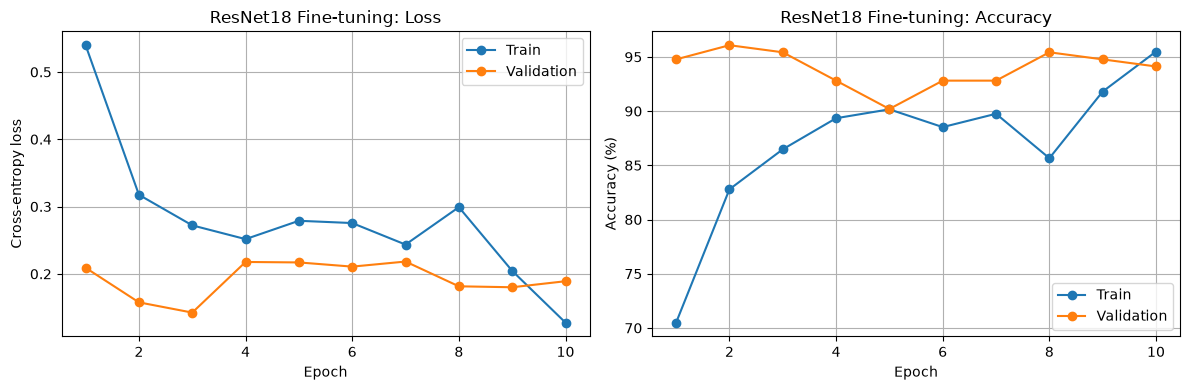

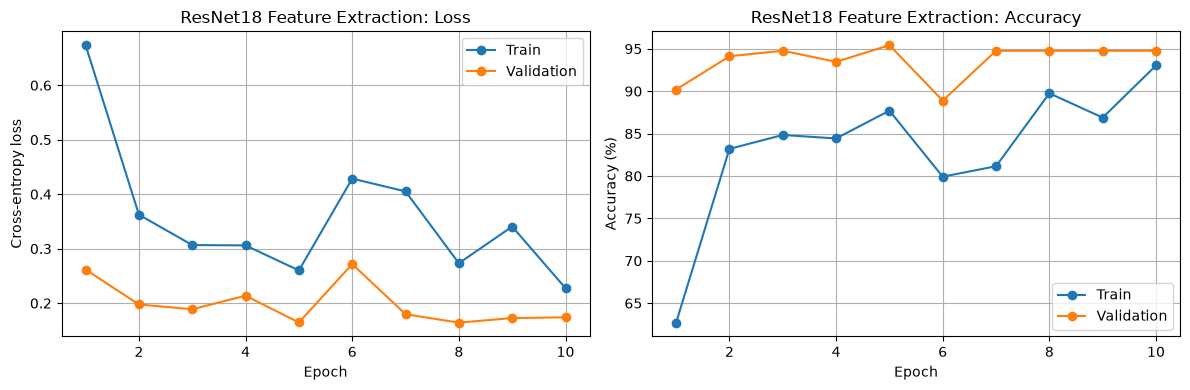


Question 3 results
Fine-tuning best validation accuracy: 96.08%
Feature extraction best validation accuracy: 95.42%


In [15]:
def plot_transfer_history(history, name):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs, history["train_loss"], marker="o", label="Train")
    axes[0].plot(epochs, history["val_loss"], marker="o", label="Validation")
    axes[0].set_title(f"{name}: Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Cross-entropy loss")
    axes[0].grid(True)
    axes[0].legend()

    axes[1].plot(epochs, history["train_acc"], marker="o", label="Train")
    axes[1].plot(epochs, history["val_acc"], marker="o", label="Validation")
    axes[1].set_title(f"{name}: Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy (%)")
    axes[1].grid(True)
    axes[1].legend()
    plt.tight_layout()
    plt.show()

plot_transfer_history(finetune_history, "ResNet18 Fine-tuning")
plot_transfer_history(feature_history, "ResNet18 Feature Extraction")

print("\nQuestion 3 results")
print(f"Fine-tuning best validation accuracy: {finetune_best_acc:.2f}%")
print(f"Feature extraction best validation accuracy: {feature_best_acc:.2f}%")

### Question 3 — Answer / discussion

**Fine-tuning** allows the model to adapt ImageNet-pretrained features to ants and bees by updating the backbone and the final classifier. This provides more flexibility but uses more computation and can overfit on a small dataset.

**Feature extraction** freezes the pretrained convolutional layers and learns only a new final classifier. It is faster and uses fewer trainable parameters, but the pretrained features cannot adapt to the new dataset.